# Praktikum 2 - Klasifikasi Naive Bayes dengan Data Dummy

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 09:** Klasifikasi

### Tujuan Praktikum:
1. Membuat data sintetis biner menggunakan `make_classification`.
2. Menerapkan model **Multinomial Naive Bayes (`MultinomialNB`)**.
3. Menerapkan model **Gaussian Naive Bayes (`GaussianNB`)** dan membandingkan performanya.

## Langkah 1 - Membuat Dataset Dummy Sintetis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

np.random.seed(42)
X, y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2,
                           n_redundant=0, n_repeated=0, shuffle=False, random_state=42)

# Transformasi nilai diskrit non-negatif
X = np.absolute(X)
X = np.round(X, 2) * 100
X = X.astype(int)

print('Sampel X (Fitur):\n', X[:5])
print('Sampel y (Label):\n', y[:5])

Sampel X (Fitur):
 [[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]]
Sampel y (Label):
 [0 0 0 0 0]


## Langkah 2 & 3 - Membuat DataFrame dan Labeling Kategorial

In [2]:
y_new = y.reshape(len(y), 1)
data_arr = np.concatenate((X, y_new), axis=1)
df = pd.DataFrame(data_arr, columns=['Fitur 1', 'Fitur 2', 'Label'])
df['Label_Kategori'] = df['Label'].map({1: 'Kelas A', 0: 'Kelas B'})
df.head()

,Fitur 1,Fitur 2,Label,Label_Kategori
0,112,139,0,Kelas B
1,179,210,0,Kelas B
2,83,71,0,Kelas B
3,182,265,0,Kelas B
4,105,78,0,Kelas B


## Langkah 4 - Visualisasi Sebaran Kelas

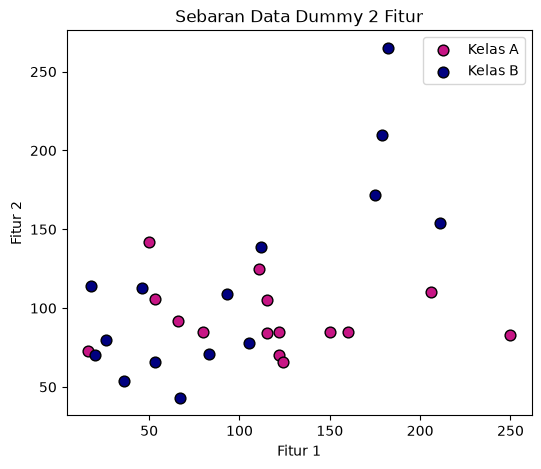

In [3]:
plt.figure(figsize=(6, 5))
class_a = df[df['Label_Kategori'] == 'Kelas A']
class_b = df[df['Label_Kategori'] == 'Kelas B']
plt.scatter(class_a['Fitur 1'], class_a['Fitur 2'], color='MediumVioletRed', label='Kelas A', s=60, edgecolors='k')
plt.scatter(class_b['Fitur 1'], class_b['Fitur 2'], color='Navy', label='Kelas B', s=60, edgecolors='k')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Sebaran Data Dummy 2 Fitur')
plt.legend()
plt.show()

## Langkah 5 - Model Multinomial Naive Bayes

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

acc_train_mnb = accuracy_score(y_train, mnb.predict(X_train))
acc_test_mnb = accuracy_score(y_test, mnb.predict(X_test))
print(f'Akurasi Train (MultinomialNB): {acc_train_mnb:.4f}')
print(f'Akurasi Test  (MultinomialNB): {acc_test_mnb:.4f}')

Akurasi Train (MultinomialNB): 0.8095
Akurasi Test  (MultinomialNB): 0.3333


## Langkah 6 - Model Gaussian Naive Bayes

In [5]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)

acc_train_gnb = accuracy_score(y_train, gnb.predict(X_train))
acc_test_gnb = accuracy_score(y_test, gnb.predict(X_test))
print(f'Akurasi Train (GaussianNB): {acc_train_gnb:.4f}')
print(f'Akurasi Test  (GaussianNB): {acc_test_gnb:.4f}')

Akurasi Train (GaussianNB): 0.8571
Akurasi Test  (GaussianNB): 0.4444
